<a href="https://colab.research.google.com/github/nrldalia/data-science-analytics-portfolio/blob/main/02_machine_learning/CustomerRetailAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 🛍️ Customer Segmentation Using K-Means Clustering

## 📌 Project Overview

This project demonstrates unsupervised machine learning by grouping synthetic retail customers according to annual income and spending score.

The project uses K-Means Clustering to identify similarities between customers and develop introductory customer segment profiles.

### 🎯 Objectives
1. Generate a reproducible synthetic customer dataset.
2. Assess and validate data quality.
3. Explore customer income and spending patterns.
4. Standardize numerical features.
5. Evaluate potential cluster counts.
6. Train a K-Means clustering model.
7. Visualize customer groups and centroids.
8. Interpret clusters using numerical summaries.
9. Discuss possible business applications and limitations.

### 🔬 Research Question

Can K-Means identify distinct customer groups based on annual income and spending behavior?

### 💡 Hypotheses

**H1:** Customers with similar income and spending characteristics can be grouped into distinct clusters.

**H2:** Standardizing the features allows both variables to contribute comparably to Euclidean-distance calculations.

**H3:** Cluster profiles can support exploratory marketing segmentation, although synthetic data cannot establish real customer behavior.

### 🧠 Machine Learning Approach

- Learning type: Unsupervised learning
- Algorithm: K-Means Clustering
- Features: Annual Income and Spending Score
- Evaluation: Inertia, silhouette score, and cluster profiles

### ⚠️ Dataset Disclaimer

All customer records are synthetically generated for educational purposes.

They do not represent real customers, transactions, or observed retail behavior.



## 🛠️ 1. Environment Setup

### Objective
Import the libraries needed for generating synthetic customer data, visualizing patterns, preprocessing features, and performing K-Means Clustering.

### Libraries
- pandas and NumPy
- Matplotlib and seaborn
- StandardScaler
- KMeans
- silhouette_score

A fixed random seed will be used to make synthetic data generation reproducible.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

OUTPUT_DIR = Path("outputs/customer_segmentation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Customer segmentation environment ready.")


Customer segmentation environment ready.



## 📥 2. Synthetic Customer Data

### Objective
Create a small reproducible dataset representing illustrative retail customer behaviors.

### Methodology
Generate 240 synthetic customers using four predefined income-spending distributions.

The generating patterns are used only to construct example data. They will not be supplied to the clustering model.

### Features
- `Annual_Income_kUSD`: Annual income in thousands of US dollars.
- `Spending_Score`: Illustrative score between 1 and 100.

### Important Limitation
The simulated patterns are intentionally designed to be distinguishable.

Consequently, strong clustering results on this dataset should not be interpreted as evidence that real retail customers naturally form the same groups.


In [2]:

# Four illustrative generating distributions:
# (mean income, mean spending score)
group_centers = [
    (30, 25),
    (30, 75),
    (80, 30),
    (80, 75)
]

records = []

for income_mean, spending_mean in group_centers:
    income = rng.normal(
        loc=income_mean,
        scale=9,
        size=60
    )

    spending = rng.normal(
        loc=spending_mean,
        scale=10,
        size=60
    )

    group = pd.DataFrame({
        "Annual_Income_kUSD": income,
        "Spending_Score": spending
    })

    records.append(group)

df_cust = pd.concat(
    records,
    ignore_index=True
)

# Enforce plausible illustrative ranges
df_cust["Annual_Income_kUSD"] = (
    df_cust["Annual_Income_kUSD"]
    .clip(lower=1)
    .round(2)
)

df_cust["Spending_Score"] = (
    df_cust["Spending_Score"]
    .clip(lower=1, upper=100)
    .round(2)
)

# Shuffle customer records
df_cust = df_cust.sample(
    frac=1,
    random_state=RANDOM_STATE
).reset_index(drop=True)

df_cust.insert(
    0,
    "Customer_ID",
    range(1, len(df_cust) + 1)
)

print("Synthetic customers:", len(df_cust))
display(df_cust.head())


Synthetic customers: 240


,Customer_ID,Annual_Income_kUSD,Spending_Score
0,1,26.15,13.04
1,2,31.15,21.51
2,3,25.62,70.16
3,4,29.63,72.13
4,5,37.55,75.90



### ✅ Data Generation Conclusion

A reproducible synthetic dataset has been created using illustrative income and spending distributions.

The dataset contains two numerical features suitable for introductory clustering.

The generating distributions were intentionally designed for educational demonstration and must not be interpreted as real customer segments.

The clustering model will receive only the observed income and spending values, not the generating group identities.



## 🧹 3. Data Quality Assessment

### Objective
Verify the completeness and validity of the synthetic dataset.

### Checks
- Missing values
- Duplicate customer identifiers
- Data types
- Income greater than zero
- Spending scores between 1 and 100

### Hypothesis
The generated data should satisfy all specified validation rules.


In [3]:

print("Dataset shape:", df_cust.shape)

print("\nMissing values:")
print(df_cust.isna().sum())

print("\nDuplicate customer IDs:")
print(df_cust["Customer_ID"].duplicated().sum())

print("\nDescriptive statistics:")
display(df_cust.describe().round(2))

assert df_cust["Customer_ID"].is_unique

assert df_cust[
    ["Annual_Income_kUSD", "Spending_Score"]
].notna().all().all()

assert (df_cust["Annual_Income_kUSD"] > 0).all()

assert df_cust["Spending_Score"].between(
    1, 100
).all()

print("\nAll data validation checks passed.")


Dataset shape: (240, 3)

Missing values:
Customer_ID           0
Annual_Income_kUSD    0
Spending_Score        0
dtype: int64

Duplicate customer IDs:
0

Descriptive statistics:


,Customer_ID,Annual_Income_kUSD,Spending_Score
count,240.00,240.00,240.00
mean,120.50,54.97,51.08
std,69.43,26.44,25.79
min,1.00,10.81,7.09
25%,60.75,30.40,27.26
50%,120.50,56.56,50.87
75%,180.25,80.47,73.69
max,240.00,106.15,100.00



All data validation checks passed.



### ✅ Data Quality Conclusion

The synthetic dataset was checked for missing observations, duplicated identifiers, and invalid numerical ranges.

The validation rules confirm that the data follows the assumptions used during generation.

Customer identifiers are retained for record tracking but will not be used as clustering features.



## 📊 4. Exploratory Data Analysis

### Objective
Examine the distribution of income and spending scores before applying clustering.

### Methodology
Plot customers in a two-dimensional scatterplot.

### Hypothesis
The synthetic data may display several distinguishable concentrations of observations.

### Limitation
Visible groups in a scatterplot do not automatically establish the optimal number of clusters.


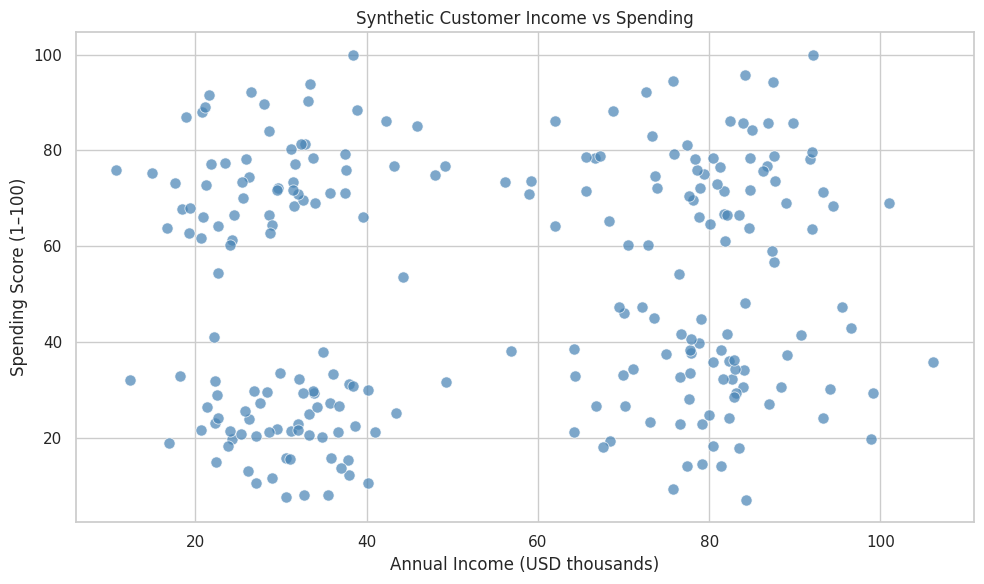

In [4]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_cust,
    x="Annual_Income_kUSD",
    y="Spending_Score",
    color="steelblue",
    alpha=0.7,
    s=65
)

plt.title("Synthetic Customer Income vs Spending")
plt.xlabel("Annual Income (USD thousands)")
plt.ylabel("Spending Score (1–100)")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "customer_distribution.png",
    dpi=150
)
plt.show()



### 🔍 Exploratory Analysis Conclusion

The scatterplot illustrates how synthetic customers are distributed across income and spending dimensions.

The data may exhibit visible concentrations because the observations were generated from distinct illustrative distributions.

Formal cluster evaluation is still needed before selecting the K-Means cluster count.



## ⚖️ 5. Feature Scaling

### Objective
Standardize income and spending scores before K-Means Clustering.

### Why Scaling Matters
K-Means uses distances between observations.

Variables with larger numerical scales can have disproportionate influence on those distances.

### Methodology
Apply StandardScaler to transform each feature using its mean and standard deviation.

The standardized features will be used for clustering, while original values will be retained for business interpretation.

### Important Note
Scaling does not guarantee meaningful clusters; it only changes how distances are calculated.


In [6]:

feature_columns = [
    "Annual_Income_kUSD",
    "Spending_Score"
]

X = df_cust[feature_columns].copy()

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

scaled_df = pd.DataFrame(
    X_scaled,
    columns=feature_columns
)

display(scaled_df.head())

print("\nScaled feature means:")
print(scaled_df.mean().round(4))

print("\nScaled feature standard deviations:")
print(scaled_df.std(ddof=0).round(4))


,Annual_Income_kUSD,Spending_Score
0,-1.092301,-1.478168
1,-0.902783,-1.149075
2,-1.112390,0.741170
3,-0.960396,0.817712
4,-0.660198,0.964191



Scaled feature means:
Annual_Income_kUSD   -0.0
Spending_Score        0.0
dtype: float64

Scaled feature standard deviations:
Annual_Income_kUSD    1.0
Spending_Score        1.0
dtype: float64



### ✅ Feature Scaling Conclusion

The numerical features were standardized before clustering.

This allows income and spending scores to contribute on comparable standardized scales to Euclidean-distance calculations.

The transformation is particularly useful for distance-based algorithms such as K-Means.

The original feature values remain available for interpreting the final customer groups.



## 🔢 6. Cluster Count Evaluation

### Objective
Compare different values of K rather than choosing the number of customer segments without evidence.

### Methodology
Evaluate K values from 2 to 8 using:

**Inertia:** Measures within-cluster squared distances. Lower values indicate tighter clusters, but inertia generally decreases as K increases.

**Silhouette Score:** Measures how well observations fit their assigned clusters compared with neighboring clusters.

Higher silhouette scores generally indicate better separation under this metric.

### Hypothesis
A relatively small number of clusters will describe the deliberately structured synthetic dataset effectively.

### Limitation
A high silhouette score does not guarantee business usefulness or reveal the true number of customer segments.


In [7]:

evaluation_results = []

for k in range(2, 9):
    candidate = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = candidate.fit_predict(X_scaled)

    evaluation_results.append({
        "K": k,
        "Inertia": candidate.inertia_,
        "Silhouette": silhouette_score(
            X_scaled,
            labels
        )
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(4))

best_k = int(
    evaluation_df.loc[
        evaluation_df["Silhouette"].idxmax(),
        "K"
    ]
)

print("Best K by silhouette score:", best_k)


,K,Inertia,Silhouette
0,2,264.1692,0.4491
1,3,142.5873,0.5222
2,4,58.1898,0.6228
3,5,51.5377,0.5533
4,6,45.0192,0.4798
5,7,39.4902,0.4508
6,8,35.7082,0.4513


Best K by silhouette score: 4


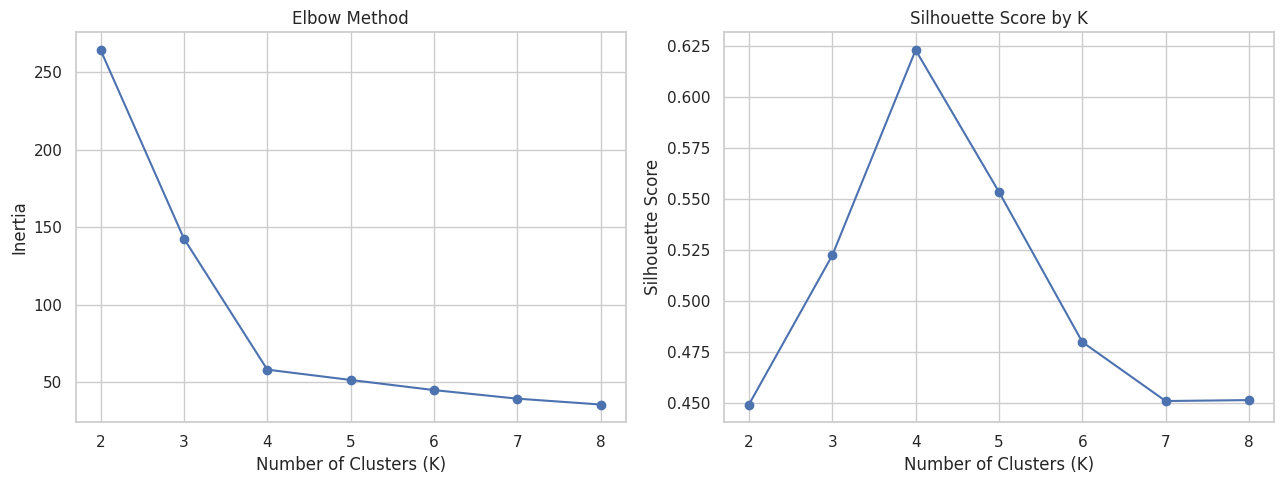

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    evaluation_df["K"],
    evaluation_df["Inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    evaluation_df["K"],
    evaluation_df["Silhouette"],
    marker="o"
)
axes[1].set_title("Silhouette Score by K")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "cluster_evaluation.png",
    dpi=150
)
plt.show()



### 📊 Cluster Evaluation Conclusion

Candidate cluster counts were evaluated using inertia and silhouette scores.

Inertia helps visualize diminishing improvements as more clusters are introduced.

The silhouette score provides an additional measure of cluster cohesion and separation.

The highest-scoring candidate will be selected for this demonstration.

This selection is based on the tested K values and chosen metric; it does not establish a universal or objectively correct number of customer segments.



## 🤖 7. K-Means Model Training

### Objective
Assign each synthetic customer to a cluster based on standardized income and spending values.

### Methodology
Train K-Means using the cluster count selected during evaluation.

The algorithm iteratively assigns observations to nearby centroids and updates centroid positions.

### Important Note
Cluster numbers are arbitrary identifiers.

For example, Cluster 0 is not automatically the lowest-income or most valuable customer group.


In [9]:

kmeans = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    n_init=10
)

df_cust["Cluster"] = kmeans.fit_predict(
    X_scaled
)

centroids_original = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centroid_df = pd.DataFrame(
    centroids_original,
    columns=feature_columns
)

centroid_df.insert(
    0,
    "Cluster",
    range(best_k)
)

print("Selected cluster count:", best_k)
print("\nCluster centroids:")
display(centroid_df.round(2))


Selected cluster count: 4

Cluster centroids:


,Cluster,Annual_Income_kUSD,Spending_Score
0,0,30.59,23.14
1,1,29.10,74.84
2,2,79.50,74.85
3,3,79.84,31.50



### ✅ Model Training Conclusion

K-Means assigned each customer to one of the selected clusters.

The centroids were transformed back into the original income and spending scales for easier interpretation.

Cluster labels are arbitrary and should be interpreted through numerical summaries rather than their assigned numbers or chart colors.



## 🎨 8. Cluster Visualization

### Objective
Visualize customer group assignments and cluster centroids.

### Methodology
Plot income against spending score, coloring each observation according to its assigned cluster.

Display centroids as X-shaped markers.

### Interpretation
Customers assigned to the same cluster are relatively similar under the model's standardized distance measure.

A chart alone is insufficient for describing the business meaning of each cluster.


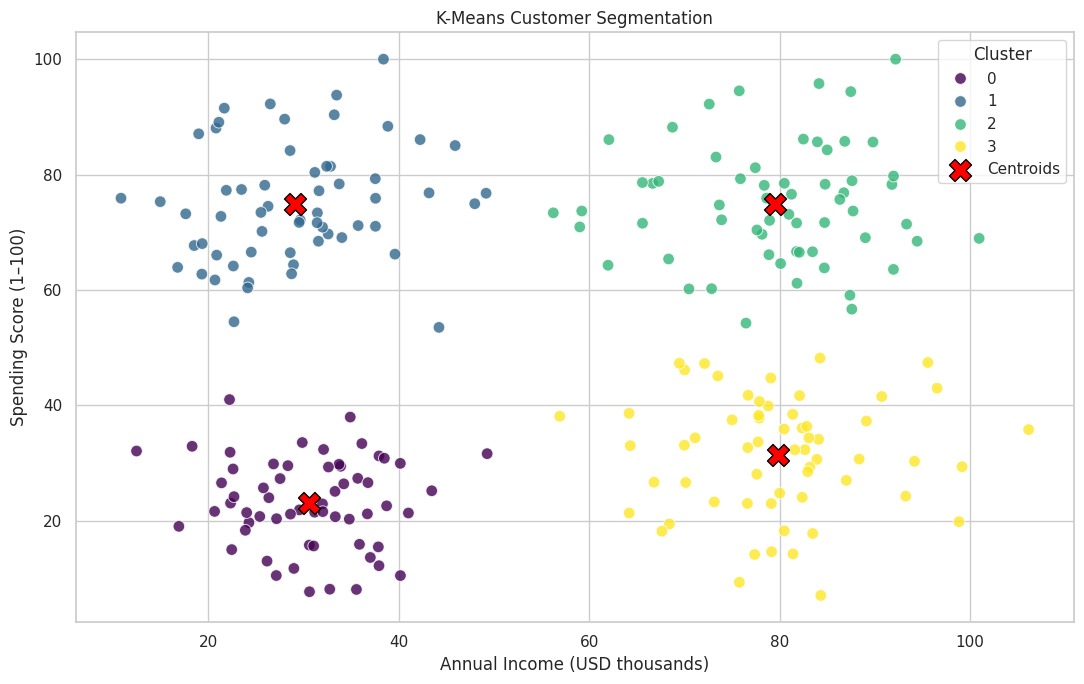

In [10]:

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df_cust,
    x="Annual_Income_kUSD",
    y="Spending_Score",
    hue="Cluster",
    palette="viridis",
    s=70,
    alpha=0.8
)

plt.scatter(
    centroid_df["Annual_Income_kUSD"],
    centroid_df["Spending_Score"],
    color="red",
    marker="X",
    s=250,
    edgecolor="black",
    label="Centroids"
)

plt.title("K-Means Customer Segmentation")
plt.xlabel("Annual Income (USD thousands)")
plt.ylabel("Spending Score (1–100)")
plt.legend(title="Cluster")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "customer_clusters.png",
    dpi=150
)
plt.show()



### 🔍 Cluster Visualization Conclusion

The visualization displays customer assignments and cluster centers.

Differences in income and spending score can be examined visually.

However, cluster colors and numeric identifiers do not carry inherent business meaning.

Numerical cluster profiles are required before proposing customer segment descriptions.



## 📋 9. Customer Segment Profiling

### Objective
Describe the characteristics of each identified customer cluster.

### Methodology
Calculate:
- Number of customers
- Average annual income
- Average spending score
- Percentage of customers

### Business Application
Cluster profiles may suggest possible marketing approaches.

These suggestions are exploratory because the dataset is synthetic and does not include real purchase history, customer preferences, or campaign outcomes.


In [11]:

cluster_profile = df_cust.groupby("Cluster").agg(
    Customer_Count=("Customer_ID", "count"),
    Average_Income=("Annual_Income_kUSD", "mean"),
    Average_Spending=("Spending_Score", "mean")
)

cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customer_Count"]
    / len(df_cust) * 100
)

display(cluster_profile.round(2))


,Customer_Count,Average_Income,Average_Spending,Customer_Percentage
Cluster,,,,
0,60,30.59,23.14,25.00
1,59,29.10,74.84,24.58
2,61,79.50,74.85,25.42
3,60,79.84,31.50,25.00


In [12]:

# Use overall sample medians as descriptive thresholds
income_threshold = df_cust["Annual_Income_kUSD"].median()
spending_threshold = df_cust["Spending_Score"].median()

def describe_segment(row):
    income_label = (
        "Higher Income"
        if row["Average_Income"] >= income_threshold
        else "Lower Income"
    )

    spending_label = (
        "Higher Spending"
        if row["Average_Spending"] >= spending_threshold
        else "Lower Spending"
    )

    return f"{income_label} / {spending_label}"

cluster_profile["Segment_Description"] = (
    cluster_profile.apply(
        describe_segment,
        axis=1
    )
)

display(cluster_profile.round(2))

print(
    "\nDescriptions are relative to this synthetic "
    "sample, not universal customer categories."
)


,Customer_Count,Average_Income,Average_Spending,Customer_Percentage,Segment_Description
Cluster,,,,,
0,60,30.59,23.14,25.00,Lower Income / Lower Spending
1,59,29.10,74.84,24.58,Lower Income / Higher Spending
2,61,79.50,74.85,25.42,Higher Income / Higher Spending
3,60,79.84,31.50,25.00,Higher Income / Lower Spending



Descriptions are relative to this synthetic sample, not universal customer categories.



### 📊 Cluster Profiling Conclusion

Cluster profiles summarize the average income, spending score, and size of each customer group.

Descriptive labels were generated using the overall sample medians as reference thresholds.

These labels are relative to the synthetic dataset and should not be interpreted as universal income or spending classifications.

The profiles provide a starting point for discussing possible customer strategies, but real business recommendations would require observed customer behavior and further validation.



## 💼 10. Potential Business Applications

### Objective
Translate customer segment characteristics into possible exploratory business actions.

### Illustrative Applications

**Higher Income / Higher Spending**
- Explore premium product offerings.
- Investigate loyalty and retention opportunities.

**Higher Income / Lower Spending**
- Explore customer preferences and barriers to engagement.
- Test personalized product recommendations.

**Lower Income / Higher Spending**
- Explore value-focused loyalty incentives.
- Investigate purchasing frequency and product preferences.

**Lower Income / Lower Spending**
- Explore affordable entry-level offers.
- Test targeted engagement campaigns.

### Important Limitation
These are hypothetical strategies, not validated recommendations.

Income and spending score alone cannot establish customer profitability, loyalty, satisfaction, or future purchasing behavior.

Any proposed action should be tested using real customer outcomes.



## 💾 11. Save and Validate Results

### Objective
Export customer assignments, cluster profiles, and evaluation results.

### Expected Outputs
- Synthetic customer dataset with cluster assignments
- Cluster profile summary
- Cluster evaluation metrics
- Cluster visualization
- Evaluation charts

### Validation
Confirm that all customers have valid cluster assignments and that the output files were created successfully.


In [13]:

df_cust.to_csv(
    OUTPUT_DIR / "customer_clusters.csv",
    index=False
)

cluster_profile.to_csv(
    OUTPUT_DIR / "cluster_profiles.csv"
)

evaluation_df.to_csv(
    OUTPUT_DIR / "cluster_evaluation.csv",
    index=False
)

assert len(df_cust) == 240
assert df_cust["Cluster"].notna().all()
assert df_cust["Cluster"].nunique() == best_k
assert cluster_profile["Customer_Count"].sum() == len(df_cust)

required_files = [
    "customer_distribution.png",
    "cluster_evaluation.png",
    "customer_clusters.png",
    "customer_clusters.csv",
    "cluster_profiles.csv",
    "cluster_evaluation.csv"
]

for filename in required_files:
    assert (OUTPUT_DIR / filename).is_file()

print("All customer clustering validation checks passed.")
print("Files saved to:", OUTPUT_DIR.resolve())


All customer clustering validation checks passed.
Files saved to: /content/outputs/customer_segmentation



## 🏁 Final Conclusion — Customer Segmentation

This project demonstrated a beginner-level unsupervised machine learning workflow using K-Means Clustering.

### Skills Demonstrated
- Synthetic data generation
- Data validation
- Exploratory visualization
- Feature standardization
- K-Means Clustering
- Cluster count evaluation
- Silhouette score interpretation
- Centroid analysis
- Customer segment profiling
- Exporting analytical outputs

### Key Learning
K-Means groups observations according to similarity in the selected feature space.

The number of clusters should be evaluated rather than selected without justification.

Cluster labels must be interpreted using their numerical characteristics.

### Limitations
- All customer records are synthetic.
- The data-generating process intentionally creates distinguishable patterns.
- Only two numerical features were used.
- No real customer transactions were analyzed.
- Business recommendations are illustrative.
- Clustering results depend on feature selection, scaling, and the chosen algorithm.

### Future Improvements
- Real customer datasets
- Additional behavioral variables
- Alternative clustering algorithms
- Cluster stability assessment
- Customer retention or campaign outcome analysis

**Project Level:** Beginner

**Machine Learning Type:** Unsupervised Learning

**Algorithm:** K-Means Clustering
